# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


In [1]:
import sys
print(sys.executable)

c:\dev\llm-data-analysis-study\llm-data-analysis-course\.venv\Scripts\python.exe


## 제출 정보
- 이름: 권혁수
- GitHub ID: kwonhyeoksoo
- 작성일: 2026-11-04
- 최종 Notebook URL: https://github.com/kwonhyeoksoo/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 1. 프로젝트 질문

### 분석 질문
1. 카테고리별 completed 금액 중 상위 2~3개 카테고리가 전체의 몇 %를 차지하며, 절반 이상을 차지하는가?
2. 월별 completed 금액이 가장 높은 달과 가장 낮은 달의 차이는 주문 수 때문인가, 주문당 평균 금액 때문인가?
3. completed 구매 금액 상위 10명이 전체 completed 금액에서 차지하는 비중은 얼마이며, 반복 구매형인가 고액 단발형인가?

### 분석 범위
completed 주문의 주문 상세만 사용한다. 주문 상태별 주문 수만 전체 주문(300건)을 사용한다.

### 사용할 데이터와 지표
| 질문 | 분석 대상 | 사용 데이터 | 지표 |
| --- | --- | --- | --- |
| 1 | 카테고리 | order_items, orders, products | 카테고리별 금액, 비중, 상위 N개 누적 비중 |
| 2 | 주문 월 | order_items, orders | 월별 금액, 고유 주문 수, 평균 주문 금액 |
| 3 | 고객(익명 라벨) | order_items, orders, customers | 고객별 금액, 주문 수, 평균 주문 금액, 상위 10명 금액 비중 |

### 계산 기준
- `order_status == "completed"` 적용 여부: 금액성 분석 전체에 적용
- `line_total = quantity × unit_price` 확인 여부: 확인 후 사용 (STEP 4에서 검증)
- total_sales는 completed 주문에 포함된 line_total 합계를 뜻하며 회계상 순매출이 아니다.

### 완료 기준
- 질문 1: 카테고리 비중 합계가 100%이고 카테고리 합계가 completed source total과 일치하면 완료
- 질문 2: 월별 합계가 completed source total과 일치하고(날짜 오류 0건), 최고/최저 달의 주문 수와 평균 주문 금액을 표에서 직접 비교했으면 완료
- 질문 3: 고객 합계가 completed source total과 일치하고 공개 결과에 원본 customer_id가 없으면 완료
- 전체: reports/ch08_project_validation.csv 모든 항목 PASS

## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: c:\dev\llm-data-analysis-study\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-study\llm-data-analysis-course
원본 데이터 폴더: C:\dev\llm-data-analysis-study\llm-data-analysis-course\data\raw
보고서 폴더: C:\dev\llm-data-analysis-study\llm-data-analysis-course\reports


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [3]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [4]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [5]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-study\llm-data-analysis-course\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-study\llm-data-analysis-course\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-study\llm-data-analysis-course\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-study\llm-data-analysis-course\data\processed\order_items_clean.csv OK


## 2. 입력 데이터와 전처리 검증
- 사용 원본 파일: data/raw/customers.csv, products.csv, orders.csv, order_items.csv
- shape: customers (150, 6), products (100, 4), orders (300, 5), order_items (764, 5)
- 핵심 결측/중복 결과: 4개 데이터셋 모두 결측 0, 전체 행 중복 0
- 전처리 전후 변화: 행 수는 4개 모두 변화 없음(150, 100, 300, 764). 열 수는 order_items 5→6(line_total 추가), orders 5→7(order_month, order_dayofweek 추가)로 늘었다. customers와 products는 변화 없음.

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단
원본이 결측과 중복 없이 깨끗해서 전처리로 제거된 행이 없다고 판단했다. 늘어난 열은 파생 컬럼이라 원본 값은 바뀌지 않았다. 전처리 결과가 있더라도 그대로 신뢰하지 않고 원본에서 다시 시작해 직접 확인했다. 행이 줄지 않았으므로 분석 결과에 미치는 영향은 없다.

### 한계와 추가 확인 사항
결측과 중복이 0이라는 것이 값의 업무적 타당성을 보장하지는 않는다. 파생 컬럼의 값(order_month 등)이 맞는지는 이 단계에서 확인하지 않았고 이후 검증 Gate에서 다룬다.

## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [6]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [7]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 3. PK/FK·병합 검증
### PK 결과
- 결측: customers.customer_id 0, products.product_id 0, orders.order_id 0, order_items.order_item_id 0
- 중복: 4개 모두 0
- PASS/FAIL: PASS (4개 모두)

### FK 결과
- 미매칭: orders.customer_id → customers.customer_id 0, order_items.order_id → orders.order_id 0, order_items.product_id → products.product_id 0
- PASS/FAIL: PASS (3개 모두)

### 병합 결과
- validate 관계: 주문 상세→주문 many_to_one, completed 상세→상품 many_to_one, 고객 집계→고객 one_to_one
- 병합 전 행 수: 764 / 474 / 100
- 병합 후 행 수: 764 / 474 / 100
- 미매칭: 0 / 0 / 0
- PASS/FAIL: PASS (3개 모두). line_total = quantity × unit_price도 764행 모두 일치(불일치 0, PASS)

### 나의 해석과 판단
세 병합 모두 validate 조건을 통과했고 병합 전후 행 수가 같으며 미매칭이 없어 안전하다고 판단했다. 병합으로 행이 늘거나 줄지 않았으므로 이후 합계가 부풀려질 위험이 낮다. line_total도 직접 재계산해 일치를 확인했다. 금액 범위는 전체 255,610,000원(764행)과 completed 148,990,000원(474행)을 구분했고, 제외된 non-completed는 106,620,000원(290행)이다. 상세 행 수(764)와 주문 수(300)도 서로 다른 값이다.

## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [8]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,21085000,23,916739.0
4,2026-01,14272000,16,892000.0
5,2026-02,4784000,7,683429.0
6,2026-03,18323000,25,732920.0
7,2026-04,10254000,15,683600.0
8,2026-05,16831000,19,885842.0
9,2026-06,12994000,17,764353.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


In [9]:
cat = category_sales.sort_values("total_sales", ascending=False).copy()
cat["cum_ratio"] = cat["sales_ratio"].cumsum().round(2)
display(cat[["category", "total_sales", "sales_ratio", "cum_ratio"]])
print("sales_ratio 합계:", round(cat["sales_ratio"].sum(), 2))

m = monthly_sales
hi = m.loc[m["total_sales"].idxmax()]
lo = m.loc[m["total_sales"].idxmin()]
print("최고 월:", hi.to_dict())
print("최저 월:", lo.to_dict())
print("금액 차이:", hi["total_sales"] - lo["total_sales"])
print("주문 수 배율:", round(hi["order_count"] / lo["order_count"], 2))
print("평균 주문 금액 배율:", round(hi["avg_order_value"] / lo["avg_order_value"], 2))
print("월별 주문 수 합계:", m["order_count"].sum())

top10 = customer_sales_public.head(10)
completed_total = category_sales["total_sales"].sum()
print("상위 10명 금액:", top10["total_sales"].sum())
print("상위 10명 비중(%):", round(top10["total_sales"].sum() / completed_total * 100, 2))
display(top10[["customer_label", "order_count", "avg_order_value"]])

,category,total_sales,sales_ratio,cum_ratio
0,스포츠,31743000,21.31,21.31
1,전자기기,26400000,17.72,39.03
2,생활용품,23915000,16.05,55.08
3,뷰티,23383000,15.69,70.77
4,식품,16573000,11.12,81.89
5,도서,16389000,11.00,92.89
6,패션,10587000,7.11,100.00


sales_ratio 합계: 100.0
최고 월: {'order_month': '2025-12', 'total_sales': 21085000, 'order_count': 23, 'avg_order_value': 916739.0}
최저 월: {'order_month': '2025-09', 'total_sales': 2650000, 'order_count': 5, 'avg_order_value': 530000.0}
금액 차이: 18435000
주문 수 배율: 4.6
평균 주문 금액 배율: 1.73
월별 주문 수 합계: 184
상위 10명 금액: 34694000
상위 10명 비중(%): 23.29


,customer_label,order_count,avg_order_value
0,Customer 01,5,820000.0
1,Customer 02,4,999000.0
2,Customer 03,4,970000.0
3,Customer 04,5,718000.0
4,Customer 05,4,880750.0
5,Customer 06,2,1595500.0
6,Customer 07,2,1589000.0
7,Customer 08,3,1051000.0
8,Customer 09,4,773250.0
9,Customer 10,2,1495000.0


## 4. 핵심 EDA 결과
### 결과 1 (카테고리별 completed 금액)
- 수치/표: 스포츠 31,743,000원(21.31%), 전자기기 26,400,000원(17.72%), 생활용품 23,915,000원(16.05%) 순. 합계 148,990,000원, 비중 합 100%
- 결과 관찰: 상위 2개 카테고리의 누적 비중은 39.03%이고, 상위 3개를 합치면 55.08%로 절반을 넘는다. 패션이 7.11%로 가장 낮다.
- 나의 해석과 판단: 금액이 한 카테고리에 쏠려 있지 않고 상위 3개가 절반 남짓을 나누는 분산된 구조로 판단했다. 스포츠가 수량(295개)도 가장 많아 금액이 수량과 함께 움직이는 것으로 보인다.
- 업무·분석적 의미: 상위 카테고리가 금액 대부분을 차지하는지 보면 어떤 상품군을 먼저 상세 분석할지 정할 수 있다.
- 한계: 금액만으로 선호도, 수익성을 말할 수 없다. 금액 차이가 수량 때문인지 단가 때문인지는 분리해서 확인하지 않았다.

### 결과 2 (월별 completed 금액과 주문 수)
- 수치/표: 최고 월 2025-12 21,085,000원(23건, 평균 916,739원), 최저 월 2025-09 2,650,000원(5건, 평균 530,000원)
- 결과 관찰: 두 달의 금액 차이는 18,435,000원이다. 주문 수는 약 4.6배, 주문당 평균 금액은 약 1.73배 차이가 났다. 주문 수 합계는 184건으로 completed 주문 수와 같다.
- 나의 해석과 판단: 최고/최저 월의 금액 차이는 평균 주문 금액보다 주문 수 차이가 더 크게 작용한 것으로 판단했다. 다만 2025-09는 데이터가 09-16부터 시작해 완전한 한 달이 아니므로 최저 월로 직접 비교하기 어렵다. 완전한 달만 보면 2026-02(4,784,000원, 7건)가 가장 낮다.
- 업무·분석적 의미: 월별 금액 변화를 볼 때 주문 수와 평균 주문 금액을 분리하면 원인 확인의 방향이 정해진다.
- 한계: 주문 수가 많거나 적은 이유(프로모션, 계절성)는 현재 데이터에 없다. 데이터가 12개월 치뿐이라 계절성을 판단할 수 없다.

### 결과 3 (completed 구매 금액 상위 고객, 익명 라벨)
- 수치/표: 상위 10명 금액 34,694,000원. 1위 Customer 01 4,100,000원(5건, 평균 820,000원)
- 결과 관찰: 상위 10명이 전체 completed 금액의 약 23.29%를 차지한다. 주문 4~5건인 고객이 6명이고, 주문 2건인 고객 3명(Customer 06, 07, 10)은 평균 주문 금액이 1,495,000~1,595,500원으로 높다.
- 나의 해석과 판단: 상위 고객은 반복 구매형과 고액 단발형이 섞여 있다고 판단했다. 상위 10명이 금액의 4분의 1 미만이라 특정 고객에 크게 의존하는 구조로 보이지 않는다.
- 업무·분석적 의미: 우수 고객을 선정할 때 총금액만이 아니라 주문 횟수와 평균 주문 금액을 함께 봐야 한다.
- 한계: 약 14개월의 짧은 기간이라 반복 구매 패턴을 일반화하기 어렵다. 충성도, 재구매 의도는 알 수 없으며, 공개 결과에는 익명 라벨과 도시만 사용했다.

## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [10]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 5. Total consistency와 날짜 검증
- completed source total: 148,990,000원
- category total: 148,990,000원
- monthly total: 148,990,000원
- customer total: 148,990,000원
- 총합 일치 여부: 일치 (4개 모두 차이 0, PASS)
- completed 주문 날짜 오류 건수: 0건
- 날짜 오류 영향 금액: 0원

### 불일치가 있었다면 원인
불일치는 없었다. 네 집계가 모두 같은 completed 주문 상세(474행)에서 출발했고, 병합 전후 행 수가 유지되었으며(미매칭 0), completed 주문에 날짜 오류가 없어 월별 합계에서 빠진 금액이 없었다. 만약 값이 달랐다면 completed 필터 누락, 병합 행 증식, FK 미매칭, category 결측, 날짜 변환 실패, 고객 연결 누락 순으로 확인했을 것이다.

## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [11]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [12]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [13]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [14]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


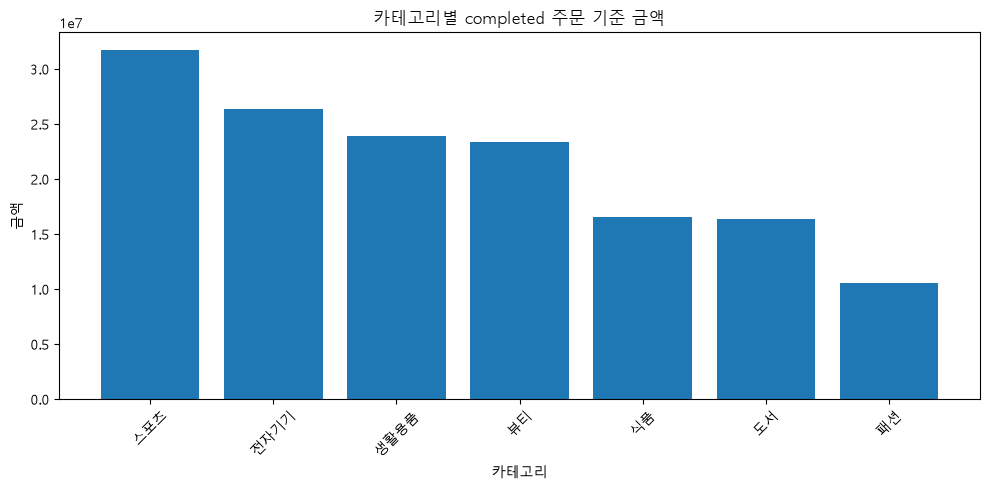

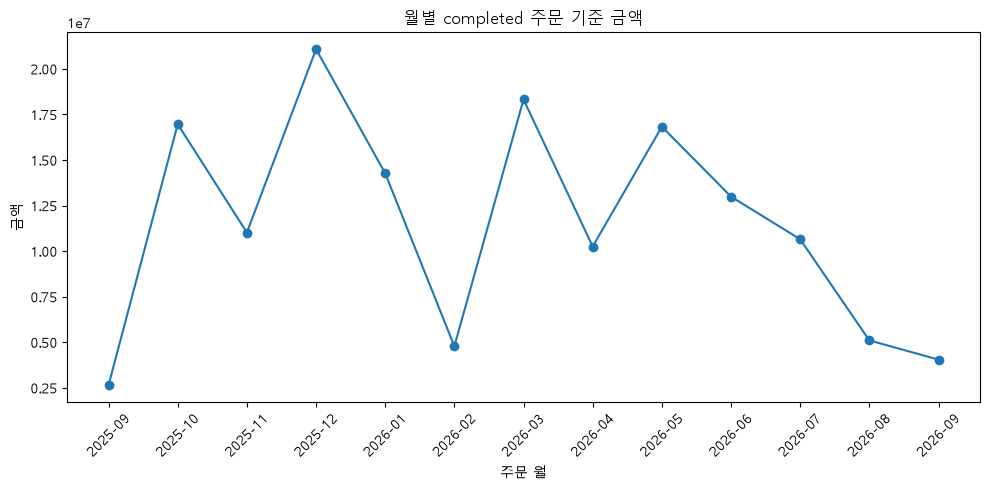

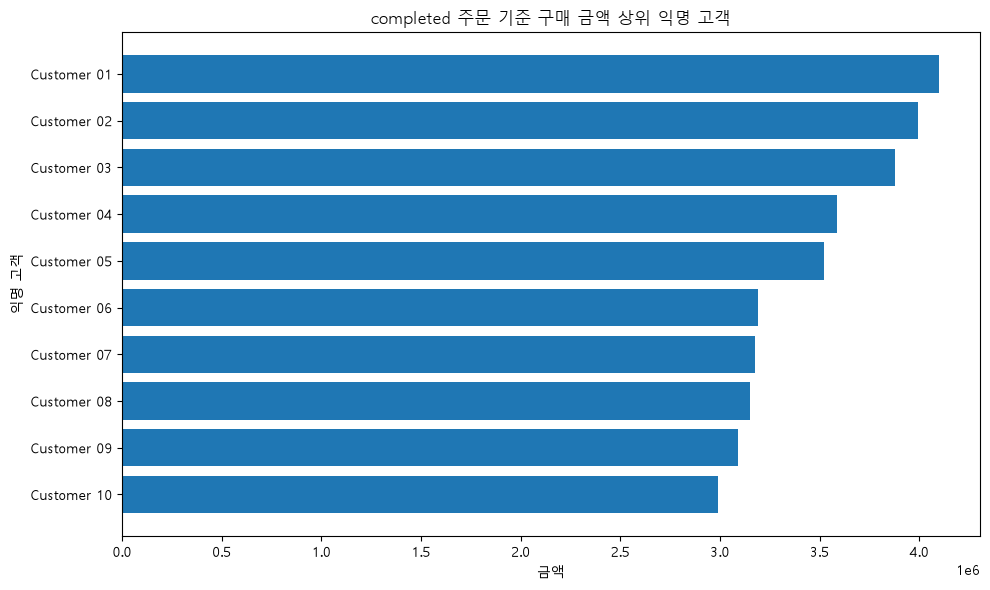

ch08_category_sales.png True 28333
ch08_monthly_sales.png True 82892
ch08_top_customers.png True 47302


In [15]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 6. 대표 시각화
![대표 그래프 1](images/graph01.png)
![대표 그래프 2](images/graph02.png)

### 그래프 선택 이유
- 그래프 1(막대): 카테고리별 금액의 크기를 비교하는 것이 목적이라 막대그래프를 선택했다.
- 그래프 2(선): 월별 금액의 시간 순서 변화를 보는 것이 목적이라 선그래프를 선택했다.
- (추가) 상위 고객 가로 막대: 순위가 있는 익명 라벨의 금액을 비교하기 쉬워 선택했다.

### 그래프와 원본 집계값 일치 여부
세 그래프 모두 집계표 값과 일치(PASS)했다. 카테고리는 스포츠 31,743,000원부터 패션 10,587,000원까지 순서가 표와 같고, 월별은 13개 월이 시간순이며 최고 2025-12(21,085,000원), 최저 2025-09(2,650,000원)가 표와 같다. 고객은 Customer 01(4,100,000원)이 1위다. 세 집계의 합계는 모두 completed source total 148,990,000원과 같다.

### 그래프에서 직접 관찰한 사실
- 카테고리: 스포츠, 전자기기, 생활용품, 뷰티 순으로 높고 패션이 가장 낮다. 상위 3개 카테고리가 전체의 55.08%다.
- 월별: 2025-12, 2026-03, 2025-10에서 금액이 높고, 2026-02와 2026-08~09에서 낮다. 증가와 감소가 번갈아 나타나 변동이 크다.
- 고객: 상위 10명의 금액이 약 300만~410만 원 범위로 1위와 10위 차이가 크지 않다.

### 그래프만으로 말할 수 없는 것
- 금액이 큰 이유가 수량인지 단가인지 알 수 없고 선호도 및 수익성도 알 수 없다.
- 월별 증감의 원인(프로모션, 계절성)은 현재 데이터에 없다. 첫 달(2025-09)과 마지막 달(2026-09)은 중간에 시작/끝나는 불완전한 달이라 낮은 값을 실제 감소로 해석하면 안 된다.
- 세 그래프의 금액 축이 지수 표기(1e7, 1e6)라 값을 정확히 읽으려면 집계표를 함께 봐야 한다.
- 고객 그래프는 상위 10명뿐이라 전체 고객 분포를 보여주지 않는다.

## 7. 개인정보 검증
- 공개 고객 CSV 컬럼: customer_label, city, order_count, total_sales, avg_order_value
- 원본 `customer_id` 포함 여부: 포함하지 않음 (메모리 결과와 저장된 reports/ch08_customer_sales.csv 모두 확인)
- 이름/이메일/전화번호/주소 포함 여부: 포함하지 않음
- 익명 라벨 방식: 금액 순위 기반 Customer 01, 02, … (원본 customer_id와 무관하게 순위로 부여)
- PASS/FAIL: PASS (섹션 9 Privacy Gate, 섹션 12 저장 CSV 재검사 모두 통과)

### 나의 판단
내부 계산에는 customer_id가 필요하지만 공개 결과에는 필요하지 않다고 판단했다. 라벨이 원본 ID가 아니라 순위로 만들어지므로 라벨에서 원본 고객을 역추적할 수 없다. 다만 city가 남아 있어 도시가 작고 고객이 적은 경우 개인이 추정될 수 있으므로 실제 업무 데이터라면 city의 공개 여부도 따로 검토해야 한다. 메모리의 DataFrame만 믿지 않고 저장된 파일을 다시 읽어 확인한 것이 이번 Gate의 핵심이었다.

## 8. 최종 Validation
`reports/ch08_project_validation.csv`의 결과를 요약합니다. (노트북 섹션 10의 project_validation 표 기준)

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | PK 4개(customer_id, product_id, order_id, order_item_id) 모두 결측 0, 중복 0 |
| fk_integrity | PASS | FK 3개 미매칭 0 |
| merge_checks_pass | PASS | 병합 3개 모두 validate 통과, 행 수 유지(764/474/100), 미매칭 0 |
| line_total_consistency | PASS | 764행 모두 quantity × unit_price와 일치(불일치 0) |
| completed_total_consistency | PASS | source, category, monthly, customer 합계가 모두 148,990,000원 |
| category_sales_ratio_pct_sum | PASS | 카테고리 비중 합 100.0% |
| completed_rows_with_invalid_order_date | PASS | completed 주문의 날짜 오류 0건, 영향 금액 0원 |
| public_customer_columns_safe | PASS | 공개 고객 결과에 금지 컬럼 없음 |

### FAIL이 있었다면 수정 내용
FAIL은 없었다. 이 기본 샘플 데이터는 결측, 중복, 키 불일치가 없어 모든 Gate가 처음 실행에서 통과했다.

## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [16]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150        

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [17]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/ch08_midterm_report.md')

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [18]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 9. LLM 활용 기록
- 사용 여부: 사용
- 사용 목적: 프로젝트 결과를 검토해 아직 확인하지 않은 위험, 과도한 해석, 보고서에 적을 계산 기준, 추가 검증 항목을 찾기 위해 사용했다.
- Safe Context: 계산 기준(line_total = quantity × unit_price, completed 범위)과 검증 결과 요약(PK 결측·중복 0, FK 미매칭 0, 병합 PASS, category·month·customer 총합 일치, completed 날짜 오류 0, 공개 고객 CSV에 원본 customer_id 없음)만 제공했다. 고객 이름 등 원본 행은 제공하지 않았다.
- Prompt 요약: 위 검증 결과를 바탕으로 (1) 아직 확인하지 않은 분석 위험, (2) 과도한 해석이 될 수 있는 표현, (3) 보고서에 적어야 할 계산 기준, (4) 추가로 필요한 검증을 요청하고, (5) 데이터에 없는 원인은 추정하지 말라고 명시했다.
- 제안 요약:
  - 위험: unit_price가 실제 결제 단가인지 알 수 없음, completed의 정의 미확인, 첫달 및 마지막 달의 불완전성, city 포함 공개 결과의 재식별 가능성, 총합 일치는 범위가 맞다는 뜻이 아니라 집계가 일관되다는 뜻
  - 피할 표현: "매출/순매출", "인기/선호", "우수/충성 고객", "프로모션 때문에 증가", "데이터가 깨끗하다"
  - 계산 기준: completed 금액과 전체 금액 구분, 주문 수는 order_id 고유 개수, 월별은 유효 날짜만, 분석 기간과 불완전한 월 표기
  - 추가 검증: 금액 차이의 수량/단가 분리, 월별 변화의 주문 수/평균 주문 금액 분해, price와 unit_price 일치 확인, 상위 고객 구매 간격, city 재식별 점검
- 반영/수정/보류:
  - 반영: 계산 기준(completed 범위, 전체 금액과 구분, 주문 수 정의), 금지 표현 대신 "completed 주문 기준 금액", "금액 상위 고객" 사용, 첫달 및 마지막 달 불완전성과 지수 표기 한계 기록, 원인 단정 금지
  - 수정: 재식별 점검은 실제로 계산하지 않고 한계 항목(city 공개 여부는 실제 업무에서 별도 검토)으로 기록
  - 보류: 상위 고객 구매 간격, 수량/단가 분리 분석은 이번 프로젝트 범위 밖이라 다음 분석 제안으로 넘김
- 사람이 검증한 근거: LLM의 제안을 그대로 쓰지 않고 실제 결과와 대조했다. 총합 4개가 148,990,000원으로 일치하고 최종 Validation 8개가 PASS임을 노트북과 스크립트에서 직접 확인했다. 저장된 공개 고객 CSV를 다시 읽어 금지 컬럼이 없음을 확인했다. 월별 표에서 2025-09가 데이터 시작일(09-16) 때문에 불완전한 달임을 직접 확인해 해석에 반영했다. LLM이 말한 '총합 일치가 범위의 정확성을 보장하지 않는다'는 점은 맞다고 판단해 해석 한계에 추가했다.

## 10. 프로젝트 재현 확인
- `python scripts/run_midterm_project.py` 실행 여부: 실행함 (가상환경에서 `python -m scripts.run_midterm_project` 형태로 실행)
- 재실행 결과: "8장 중간 프로젝트 완료"가 출력되었고 최종 Validation 8개 항목이 모두 PASS였다. 결과표 15개, 그래프 3개, 보고서 1개가 저장되었다.
- Notebook과 핵심 수치 일치 여부: 일치. 병합 행 수(764/474/100), 전체 금액 255,610,000원, completed 금액 148,990,000원, 총합 4개 148,990,000원, 카테고리·월별 표 값이 노트북 결과와 같았다. 노트북 섹션 15의 run_midterm_project() 재실행도 같은 결과였다.
- 생성된 핵심 Evidence 파일 확인 여부: 확인함 (ch08_project_validation.csv, ch08_total_consistency_check.csv, ch08_date_checks.csv 등, 섹션 16 산출물 검증 반영)

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단
노트북은 셀을 여러 번 실행하면 이전 값이 메모리에 남아 결과가 달라질 수 있다. 원본부터 한 번에 다시 실행하는 스크립트에서 같은 수치와 PASS가 나왔다는 것은 결과가 특정 실행 순서에 의존하지 않고 재현된다는 뜻이다. 노트북과 스크립트가 같은 src.midterm_project 함수를 쓰기 때문에 계산 기준이 어긋나지 않는다고 판단했다. 재현 가능해야 다른 사람이 같은 검증을 반복할 수 있다.

## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [19]:
# 실습 과제 코드를 아래에 작성하세요.
for name in ["ch08_total_consistency_check.csv", "ch08_project_validation.csv"]:
    print(f"\n===== {name} =====")
    display(pd.read_csv(REPORT_DIR / name))


===== ch08_total_consistency_check.csv =====


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS



===== ch08_project_validation.csv =====


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


### 실습 과제 기록

1. 핵심 EDA 결과 3개: 카테고리별 금액(4번 결과 1), 월별 금액과 주문 수(결과 2), 상위 고객 금액(결과 3)을 선택했고 각각 근거와 한계를 4번 섹션에 작성했다.
2. 대표 그래프: 카테고리 막대, 월별 선, 상위 익명 고객 가로 막대 3개를 선택했고 집계표 값과 일치함을 6번 섹션에서 확인했다.
3. total consistency와 project validation: 저장된 두 CSV를 다시 읽어 확인했다. 총합 4개가 148,990,000원으로 일치하고 Validation 8개가 모두 PASS였다.
4. 개인정보: 저장된 ch08_customer_sales.csv를 다시 읽어 금지 컬럼이 없음을 확인했다(7번 섹션).
5. LLM 기록: 9번 섹션에 작성했다.
6. 전체 재실행: python -m scripts.run_midterm_project를 실행해 노트북과 같은 수치와 PASS를 확인했다(10번 섹션).

## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 
- 관찰: completed 주문 기준 금액은 스포츠 31,743,000원(21.31%), 전자기기 26,400,000원(17.72%), 생활용품 23,915,000원(16.05%) 순이고, 상위 3개 카테고리의 누적 비중은 55.08%다.
- 해석: 금액이 한 카테고리에 쏠리지 않고 상위 3개가 절반 남짓을 나누는 구조다.
- 근거: 카테고리 합계 148,990,000원이 completed source total과 일치하고 비중 합이 100%다.
2. 
- 관찰: 월별 최고는 2025-12(21,085,000원, 23건), 최저는 2025-09(2,650,000원, 5건)이며, 주문 수는 약 4.6배, 평균 주문 금액은 약 1.73배 차이가 났다.
- 해석: 두 달의 금액 차이는 평균 주문 금액보다 주문 수 차이가 더 크게 작용한 것으로 보인다.
- 근거: 월별 표의 주문 수와 평균 주문 금액, 월별 합계가 source total과 일치한다. 2025-09는 09-16부터 시작해 불완전한 달이다.
- 보완: 완전한 달만 비교하면 최고 2025-12(21,085,000원, 23건)와 최저 2026-02(4,784,000원, 7건)는 주문 수 약 3.3배, 평균 주문 금액 약 1.34배 차이로, 이 경우에도 주문 수 차이가 더 크다.
3. 
- 관찰: 금액 상위 10명이 전체 completed 금액의 약 23.29%(34,694,000원)를 차지하고 반복 구매형(4~5건)과 고액 단발형(2건, 평균 약 150만 원)이 섞여 있다.
- 해석: 특정 고객에 크게 의존하는 구조는 아닌 것으로 보인다.
- 근거: 고객 합계가 source total과 일치하고 공개 결과에 원본 customer_id가 없다.

### 가장 중요한 업무·분석적 의미
같은 의미의 숫자(completed source, 카테고리, 월별, 고객 합계)가 서로 다른 집계에서도 같다는 것을 검증해야 결과를 신뢰할 수 있다. 전체 금액(255,610,000원)과 completed 금액(148,990,000원)을 구분하지 않으면 금액이 약 1.7배 과대 집계된다.

### 현재 분석의 한계
- 금액은 completed 주문 상세의 line_total 합계이며 순매출·수익이 아니다(할인, 배송비, 환불 수수료 정보 없음).
- 금액 차이가 수량 때문인지 단가 때문인지 분리하지 않았다.
- 12개월 데이터라 계절성을 판단할 수 없고 월별 증감의 원인(프로모션 등)은 데이터에 없다.
- 총합 일치는 집계의 일관성을 보여 줄 뿐 completed 정의 자체의 타당성을 보장하지 않는다.
- 공개 결과에 city가 포함되어 있어 재식별 가능성은 별도 검토가 필요하다.

### 다음 분석 제안
1. 카테고리별 판매 수량과 평균 단가를 분리해 금액 차이의 원인을 확인한다.
2. 월별 카테고리 구성을 비교해 특정 달의 금액 변화에 기여한 카테고리를 찾는다.
3. 상위 고객의 구매 간격과 반복 구매 여부를 확인한다.

## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```


## 최종 체크
- [x] 질문과 지표가 연결됩니다.
- [x] 원본 데이터에서 다시 시작했습니다.
- [x] PK/FK·병합 검증 근거가 있습니다.
- [x] `line_total` 계산 관계를 확인했습니다.
- [x] 금액성 분석은 completed 범위를 사용했습니다.
- [x] category/month/customer 총합이 source total과 일치합니다.
- [x] 날짜 오류를 확인했습니다.
- [x] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [x] 대표 그래프와 원본 집계값을 비교했습니다.
- [x] 원인 과대 해석이 없습니다.
- [x] 최종 Validation이 모두 PASS입니다.
- [x] 전체 프로젝트를 재실행했습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.